In [1]:
# ---------------------------------------------------------------
# Imports and Configuration
# ---------------------------------------------------------------
from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

INPUT_PATH = Path("baseline_engineered.parquet")      # from Baseline2 notebook (Section 6.3)
FEATURE_LIST_PATH = Path("engineered_feature_cols.json")

WINDOW_LENGTH = 120       # minutes; starting point informed by Section 4.3's 60-min ACF still >0.88
WINDOW_STRIDE = 30        # non-overlapping-ish stride to keep window count tractable
MAX_WINDOWS_PER_CLASS = 15_000   # training-set cap, same spirit as the baseline's SAMPLE_SIZE
BATCH_SIZE = 256

Using device: cuda


In [2]:
# ---------------------------------------------------------------
# Load only the columns needed: engineered features + fault_type +
# Datetime + source_file + n_chillers_on. Same column-pushdown
# lesson learned in the baseline notebook — avoids materializing
# the full ~56-column frame when only ~55 are actually needed here.
# ---------------------------------------------------------------
with open(FEATURE_LIST_PATH) as f:
    engineered_feature_cols = json.load(f)

needed_cols = list(set(
    engineered_feature_cols + ["fault_type", "Datetime", "source_file", "n_chillers_on"]
))

data = pd.read_parquet(INPUT_PATH, columns=needed_cols)
print(f"Loaded: {data.shape[0]:,} rows, {data.shape[1]} columns")
print(f"Feature count: {len(engineered_feature_cols)}")

Loaded: 12,612,960 rows, 53 columns
Feature count: 50


In [3]:
# ---------------------------------------------------------------
# Train/validation/test split — same contiguous month-block
# strategy as the baseline (Section 6), to keep the comparison in
# Table 2 valid (identical split across all candidates)
# ---------------------------------------------------------------
data["month"] = data["Datetime"].dt.month
data = data.sort_values(["source_file", "Datetime"]).reset_index(drop=True)

train_months = list(range(1, 9))
val_months = [9, 10]
test_months = [11, 12]

data["split"] = np.select(
    [data["month"].isin(train_months), data["month"].isin(val_months), data["month"].isin(test_months)],
    ["train", "val", "test"],
    default="unused",
)
print(data["split"].value_counts())

split
train    8396640
val      2108160
test     2108160
Name: count, dtype: int64


In [4]:
# ---------------------------------------------------------------
# Window construction — respects scenario (source_file) boundaries.
# Uses a plain loop over groupby() for sampling, avoiding any
# .apply()-related column-dropping issues entirely.
# ---------------------------------------------------------------
def build_window_index(df, split_name, window_length, stride, max_per_class=None, random_state=RANDOM_STATE):
    windows = []
    split_df = df[df["split"] == split_name]

    for source_file, group in split_df.groupby("source_file", sort=False):
        group = group.sort_values("Datetime")
        n = len(group)
        if n < window_length:
            continue
        idx = group.index.to_numpy()
        label = group["fault_type"].iloc[0]
        for start in range(0, n - window_length + 1, stride):
            windows.append((idx[start:start + window_length], label))

    windows_df = pd.DataFrame(windows, columns=["row_idx", "fault_type"])

    if max_per_class is not None:
        sampled_parts = []
        for fault_type, group in windows_df.groupby("fault_type"):
            sampled_parts.append(
                group.sample(n=min(len(group), max_per_class), random_state=random_state)
            )
        windows_df = pd.concat(sampled_parts, ignore_index=True)

    return windows_df.reset_index(drop=True)

In [5]:
# ---------------------------------------------------------------
# Build the train/validation window indices using the function
# defined above
# ---------------------------------------------------------------
train_windows = build_window_index(data, "train", WINDOW_LENGTH, WINDOW_STRIDE, max_per_class=MAX_WINDOWS_PER_CLASS)
val_windows = build_window_index(data, "val", WINDOW_LENGTH, WINDOW_STRIDE, max_per_class=None)

print(f"Train windows: {len(train_windows):,}")
print(train_windows["fault_type"].value_counts())
print(f"\nValidation windows: {len(val_windows):,}")

Train windows: 128,318
fault_type
bypass_leakage                           15000
bypass_stuck                             15000
chiller_bias                             15000
chiller_fouling                          15000
coolingtower_bias                        15000
coolingtower_fouling                     15000
secondary_chilled_water_pressure_bias    15000
coolingtower_PI                          11659
fault_free                               11659
Name: count, dtype: int64

Validation windows: 70,200


In [6]:
# ---------------------------------------------------------------
# Feature scaling — fit RobustScaler on a sample of training rows
# only (not full training windows, to avoid re-materializing a huge
# array), consistent with the robust-scaling justification in
# Section 4.1 (heavy skewness)
# ---------------------------------------------------------------
fit_sample_idx = data[data["split"] == "train"].sample(n=200_000, random_state=RANDOM_STATE).index
scaler = RobustScaler()
scaler.fit(data.loc[fit_sample_idx, engineered_feature_cols].astype(np.float32))

label_encoder = LabelEncoder()
label_encoder.fit(data["fault_type"])
print(f"Classes: {list(label_encoder.classes_)}")

Classes: ['bypass_leakage', 'bypass_stuck', 'chiller_bias', 'chiller_fouling', 'coolingtower_PI', 'coolingtower_bias', 'coolingtower_fouling', 'fault_free', 'secondary_chilled_water_pressure_bias']


In [7]:
# ---------------------------------------------------------------
# PyTorch Dataset — builds each window's feature array and label
# ON DEMAND (in __getitem__), not all at once, so GPU/CPU memory
# only ever holds one batch at a time. Feature matrix for the whole
# split is held once as a float32 numpy array (not per-window copies).
# ---------------------------------------------------------------
class ChillerWindowDataset(Dataset):
    def __init__(self, df, windows_df, feature_cols, scaler, label_encoder):
        self.feature_matrix = scaler.transform(
            df[feature_cols].astype(np.float32)
        ).astype(np.float32)
        self.labels = label_encoder.transform(windows_df["fault_type"].values)
        self.row_idx_list = windows_df["row_idx"].values
        # map original df index -> position in feature_matrix
        self.pos_lookup = pd.Series(np.arange(len(df)), index=df.index)

    def __len__(self):
        return len(self.row_idx_list)

    def __getitem__(self, i):
        positions = self.pos_lookup.loc[self.row_idx_list[i]].values
        x = self.feature_matrix[positions]          # (window_length, n_features)
        y = self.labels[i]
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)


train_dataset = ChillerWindowDataset(data, train_windows, engineered_feature_cols, scaler, label_encoder)
val_dataset = ChillerWindowDataset(data, val_windows, engineered_feature_cols, scaler, label_encoder)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 502, Val batches: 275


In [8]:
# ---------------------------------------------------------------
# Class weights for the loss function, per Section 6.2's weighted
# cross-entropy specification — addresses the Section 4.1 imbalance
# ---------------------------------------------------------------
class_counts = train_windows["fault_type"].value_counts().reindex(label_encoder.classes_)
class_weights = (len(train_windows) / (len(label_encoder.classes_) * class_counts)).values
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print(pd.Series(class_weights, index=label_encoder.classes_).round(3))

bypass_leakage                           0.951
bypass_stuck                             0.951
chiller_bias                             0.951
chiller_fouling                          0.951
coolingtower_PI                          1.223
coolingtower_bias                        0.951
coolingtower_fouling                     0.951
fault_free                               1.223
secondary_chilled_water_pressure_bias    0.951
dtype: float64


In [9]:
# ---------------------------------------------------------------
# Candidate Model 1: LSTM classifier — per Section 6.2's gate
# equations (f, i, o, c, h), final hidden state -> FC -> softmax
# ---------------------------------------------------------------
class LSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1, n_classes=9, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, n_classes)

    def forward(self, x):
        # x: (batch, window_length, n_features)
        _, (h_n, _) = self.lstm(x)
        h_last = h_n[-1]                 # final layer's hidden state, h_w from Section 6.2
        h_last = self.dropout(h_last)
        logits = self.fc(h_last)         # z = W_out h_w + b_out
        return logits                    # softmax applied inside CrossEntropyLoss

In [10]:
# ---------------------------------------------------------------
# Candidate Model 2: 1D-CNN classifier — per Section 6.2's
# convolution-over-time formulation, followed by global pooling
# and the same FC + softmax output layer
# ---------------------------------------------------------------
class CNN1DClassifier(nn.Module):
    def __init__(self, n_features, n_classes=9, channels=(64, 128), kernel_size=5, dropout=0.2):
        super().__init__()
        layers = []
        in_ch = n_features
        for out_ch in channels:
            layers += [
                nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=kernel_size // 2),
                nn.ReLU(),
                nn.BatchNorm1d(out_ch),
            ]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], n_classes)

    def forward(self, x):
        # x: (batch, window_length, n_features) -> (batch, n_features, window_length)
        x = x.permute(0, 2, 1)
        x = self.conv(x)
        x = self.pool(x).squeeze(-1)
        x = self.dropout(x)
        logits = self.fc(x)
        return logits

In [11]:
# ---------------------------------------------------------------
# Shared training loop — used for both candidates, with early
# stopping on validation loss (Section 6, "Define the Training
# Procedure"), so the two architectures are compared under an
# identical training procedure
# ---------------------------------------------------------------
def train_model(model, train_loader, val_loader, class_weights_t, max_epochs=30, patience=5, lr=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights_t)

    best_val_loss = float("inf")
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                loss = criterion(logits, yb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} — train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(best_state)
    return model, history

In [12]:
# ---------------------------------------------------------------
# Train Candidate Model 1: LSTM
# ---------------------------------------------------------------
n_classes = len(label_encoder.classes_)
n_features = len(engineered_feature_cols)

lstm_model = LSTMClassifier(n_features=n_features, hidden_size=64, num_layers=1, n_classes=n_classes)
lstm_model, lstm_history = train_model(lstm_model, train_loader, val_loader, class_weights_t)

Epoch 1/30 — train_loss: 1.5787, val_loss: 1.3984
Epoch 2/30 — train_loss: 1.3944, val_loss: 1.4034
Epoch 3/30 — train_loss: 1.3326, val_loss: 1.4162
Epoch 4/30 — train_loss: 1.2909, val_loss: 1.3287
Epoch 5/30 — train_loss: 1.2924, val_loss: 1.3218
Epoch 6/30 — train_loss: 1.2057, val_loss: 1.3575
Epoch 7/30 — train_loss: 1.1991, val_loss: 1.3348
Epoch 8/30 — train_loss: 1.1434, val_loss: 1.2331
Epoch 9/30 — train_loss: 1.1853, val_loss: 1.2989
Epoch 10/30 — train_loss: 1.1183, val_loss: 1.2847
Epoch 11/30 — train_loss: 1.1015, val_loss: 1.2465
Epoch 12/30 — train_loss: 1.0960, val_loss: 1.2354
Epoch 13/30 — train_loss: 1.3858, val_loss: 1.2471
Early stopping at epoch 13


In [13]:
# ---------------------------------------------------------------
# Train Candidate Model 2: 1D-CNN
# ---------------------------------------------------------------
cnn_model = CNN1DClassifier(n_features=n_features, n_classes=n_classes, channels=(64, 128))
cnn_model, cnn_history = train_model(cnn_model, train_loader, val_loader, class_weights_t)

Epoch 1/30 — train_loss: 1.4997, val_loss: 1.5331
Epoch 2/30 — train_loss: 1.1884, val_loss: 1.4595
Epoch 3/30 — train_loss: 1.0560, val_loss: 1.4631
Epoch 4/30 — train_loss: 1.0053, val_loss: 1.4744
Epoch 5/30 — train_loss: 0.9727, val_loss: 1.4763
Epoch 6/30 — train_loss: 0.9338, val_loss: 1.3322
Epoch 7/30 — train_loss: 0.9113, val_loss: 1.2946
Epoch 8/30 — train_loss: 0.8959, val_loss: 1.1928
Epoch 9/30 — train_loss: 0.8698, val_loss: 1.1985
Epoch 10/30 — train_loss: 0.8542, val_loss: 1.2273
Epoch 11/30 — train_loss: 0.8408, val_loss: 1.2448
Epoch 12/30 — train_loss: 0.8203, val_loss: 1.0639
Epoch 13/30 — train_loss: 0.8145, val_loss: 1.1507
Epoch 14/30 — train_loss: 0.7966, val_loss: 1.0851
Epoch 15/30 — train_loss: 0.8401, val_loss: 1.0604
Epoch 16/30 — train_loss: 0.7951, val_loss: 1.0084
Epoch 17/30 — train_loss: 0.7774, val_loss: 0.9863
Epoch 18/30 — train_loss: 0.7703, val_loss: 0.9961
Epoch 19/30 — train_loss: 0.7678, val_loss: 1.0523
Epoch 20/30 — train_loss: 0.7587, val_lo

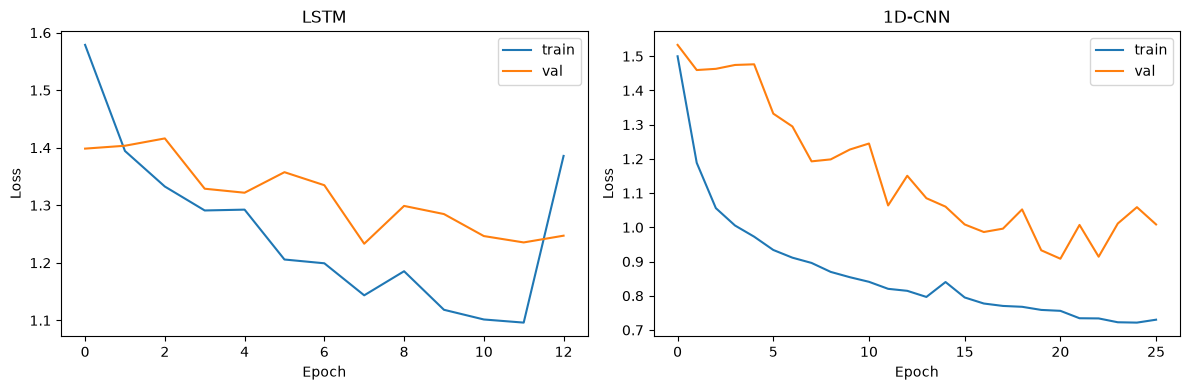

In [14]:
# ---------------------------------------------------------------
# Training curves — quick sanity check both models actually
# converged before trusting their validation metrics
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, history, title in [(axes[0], lstm_history, "LSTM"), (axes[1], cnn_history, "1D-CNN")]:
    ax.plot(history["train_loss"], label="train")
    ax.plot(history["val_loss"], label="val")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# ---------------------------------------------------------------
# Shared evaluation function — per-class metrics, confusion matrix,
# per the evaluation criteria defined in Section VI
# ---------------------------------------------------------------
def evaluate_model(model, loader, label_encoder):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(yb.numpy())
    y_pred = label_encoder.inverse_transform(np.concatenate(all_preds))
    y_true = label_encoder.inverse_transform(np.concatenate(all_labels))
    return y_true, y_pred


y_val_true_lstm, y_val_pred_lstm = evaluate_model(lstm_model, val_loader, label_encoder)
y_val_true_cnn, y_val_pred_cnn = evaluate_model(cnn_model, val_loader, label_encoder)

print("=== LSTM — Validation Performance ===")
print(classification_report(y_val_true_lstm, y_val_pred_lstm, digits=3))

print("\n=== 1D-CNN — Validation Performance ===")
print(classification_report(y_val_true_cnn, y_val_pred_cnn, digits=3))

=== LSTM — Validation Performance ===
                                       precision    recall  f1-score   support

                       bypass_leakage      0.885     0.714     0.790      8775
                         bypass_stuck      0.669     0.851     0.749      5850
                         chiller_bias      0.735     0.679     0.706     11700
                      chiller_fouling      0.520     0.114     0.187      5850
                      coolingtower_PI      0.437     0.276     0.339      2925
                    coolingtower_bias      0.644     0.382     0.480     11700
                 coolingtower_fouling      0.279     0.433     0.339      8775
                           fault_free      0.088     0.464     0.147      2925
secondary_chilled_water_pressure_bias      0.756     0.368     0.495     11700

                             accuracy                          0.493     70200
                            macro avg      0.557     0.476     0.470     70200
            

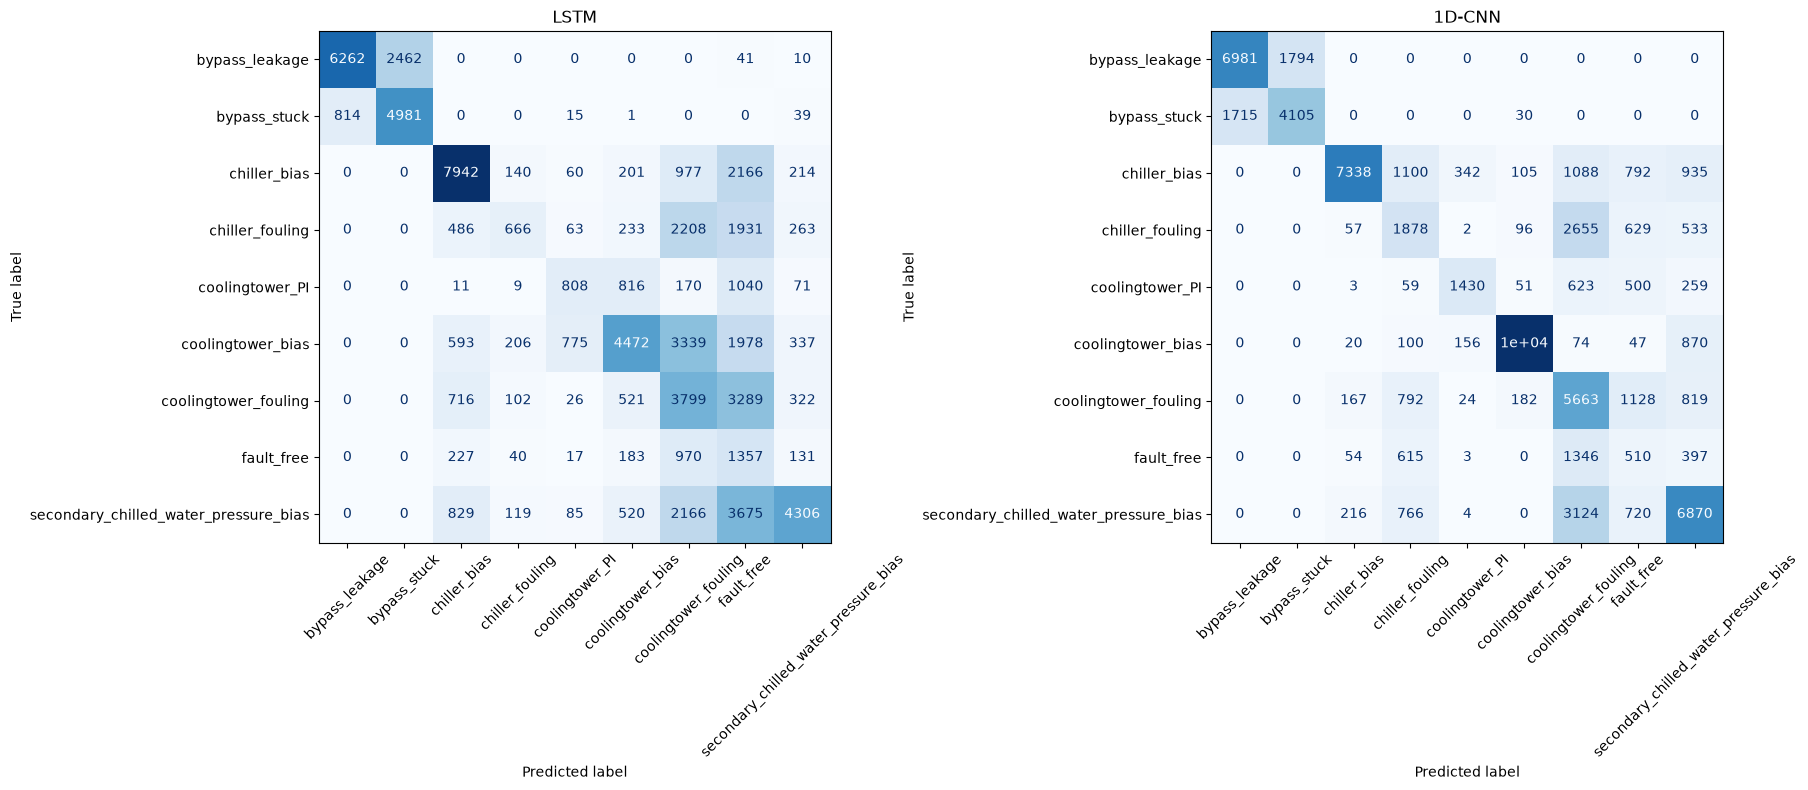

In [16]:
# ---------------------------------------------------------------
# Confusion matrices — side by side, per Section VI evaluation
# criteria
# ---------------------------------------------------------------
labels_sorted = sorted(label_encoder.classes_)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, y_true, y_pred, title in [
    (axes[0], y_val_true_lstm, y_val_pred_lstm, "LSTM"),
    (axes[1], y_val_true_cnn, y_val_pred_cnn, "1D-CNN"),
]:
    cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
    ConfusionMatrixDisplay(cm, display_labels=labels_sorted).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [17]:
# ---------------------------------------------------------------
# Regime-conditioned evaluation — directly tests whether either
# sequence-aware candidate reintroduces reliance on staging regime
# as a shortcut, per Section VI and the Section 6.3 resolution this
# is meant to confirm rather than rediscover. Uses each window's
# LAST row's staging state as the regime label for that window.
# ---------------------------------------------------------------
def regime_conditioned_eval(windows_df, y_true, y_pred, data):
    last_row_idx = windows_df["row_idx"].apply(lambda arr: arr[-1])
    regimes = data.loc[last_row_idx, "n_chillers_on"].values

    results = []
    for regime in sorted(np.unique(regimes)):
        mask = regimes == regime
        if mask.sum() < 50:
            continue
        report = classification_report(y_true[mask], y_pred[mask], output_dict=True, zero_division=0)
        results.append({"n_chillers_on": regime, "n": mask.sum(),
                         "accuracy": report["accuracy"], "macro_f1": report["macro avg"]["f1-score"]})
    return pd.DataFrame(results)

print("LSTM — regime-conditioned performance:")
print(regime_conditioned_eval(val_windows, y_val_true_lstm, y_val_pred_lstm, data))

print("\n1D-CNN — regime-conditioned performance:")
print(regime_conditioned_eval(val_windows, y_val_true_cnn, y_val_pred_cnn, data))

LSTM — regime-conditioned performance:
   n_chillers_on      n  accuracy  macro_f1
0            1.0  65452  0.519067  0.482784
1            2.0   4712  0.129669  0.182597

1D-CNN — regime-conditioned performance:
   n_chillers_on      n  accuracy  macro_f1
0            1.0  65452  0.667023  0.611332
1            2.0   4712  0.327250  0.332994


In [18]:
# ---------------------------------------------------------------
# Comparison table against the already-established baseline
# (Section 6.3) — loads the saved baseline results rather than
# retraining, per the "Results Saved" pattern used throughout
# ---------------------------------------------------------------
with open("baseline_results.json") as f:
    baseline_results = json.load(f)

report_baseline = baseline_results["reduced_regime_dev"]
report_lstm = classification_report(y_val_true_lstm, y_val_pred_lstm, output_dict=True)
report_cnn = classification_report(y_val_true_cnn, y_val_pred_cnn, output_dict=True)

all_classes = sorted(label_encoder.classes_)
comparison = pd.DataFrame({
    "Baseline (RF)": [report_baseline[c]["f1-score"] for c in all_classes],
    "Candidate 1 (LSTM)": [report_lstm[c]["f1-score"] for c in all_classes],
    "Candidate 2 (1D-CNN)": [report_cnn[c]["f1-score"] for c in all_classes],
}, index=all_classes)
comparison.loc["Accuracy"] = [report_baseline["accuracy"], report_lstm["accuracy"], report_cnn["accuracy"]]
comparison.loc["Macro F1"] = [
    report_baseline["macro avg"]["f1-score"],
    report_lstm["macro avg"]["f1-score"],
    report_cnn["macro avg"]["f1-score"],
]
print(comparison.round(3))

                                       Baseline (RF)  Candidate 1 (LSTM)  Candidate 2 (1D-CNN)
bypass_leakage                                 1.000               0.790                 0.799
bypass_stuck                                   1.000               0.749                 0.699
chiller_bias                                   0.793               0.706                 0.750
chiller_fouling                                0.695               0.187                 0.337
coolingtower_PI                                0.271               0.339                 0.585
coolingtower_bias                              0.664               0.480                 0.923
coolingtower_fouling                           0.460               0.339                 0.485
fault_free                                     0.058               0.147                 0.141
secondary_chilled_water_pressure_bias          0.766               0.495                 0.614
Accuracy                                       0.7

In [19]:
# ---------------------------------------------------------------
# Results Saved — persist models, predictions, and comparison
# table for the explainability analysis / results write-up
# ---------------------------------------------------------------
torch.save(lstm_model.state_dict(), "lstm_model.pt")
torch.save(cnn_model.state_dict(), "cnn_model.pt")

model_results = {
    "candidate_1_lstm": classification_report(y_val_true_lstm, y_val_pred_lstm, output_dict=True),
    "candidate_2_cnn": classification_report(y_val_true_cnn, y_val_pred_cnn, output_dict=True),
}
with open("sequence_model_results.json", "w") as f:
    json.dump(model_results, f, indent=2)

comparison.to_csv("model_comparison_table.csv")

print("Saved: lstm_model.pt, cnn_model.pt, sequence_model_results.json, model_comparison_table.csv")

Saved: lstm_model.pt, cnn_model.pt, sequence_model_results.json, model_comparison_table.csv
